In [29]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import emd
import h5py
import json

import statistics

import numpy as np
from numpy.fft import fft, ifft
from scipy.interpolate import interp1d
from scipy import signal
from scipy.signal import butter, filtfilt

import pycbc
from pycbc import noise
from pycbc.waveform import get_fd_waveform, get_waveform_filter_length_in_time as chirplen
from pycbc.waveform.generator import (FDomainDetFrameGenerator, FDomainCBCGenerator)
from pycbc.psd import aLIGOZeroDetHighPower, AdVDesignSensitivityP1200087
from pycbc.noise.gaussian import frequency_noise_from_psd
from pycbc.filter.matchedfilter import matched_filter
import lal

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.mlab as mlab

# plotting items
%matplotlib inline


In [30]:
def whiten(freqSeries, psd):
    """Whiten a given freqSeries
    """

    dt = 1./freqSeries.sample_rate
    norm = 1./np.sqrt(1./(dt*2))
    white_hf = freqSeries / np.sqrt(psd.data) * norm
    white_ts = (white_hf).to_timeseries()

    return white_ts

def bandpass(strain, fband, fs):
    """Bandpasses strain data using a butterworth filter.

    Args:
        strain (ndarray): strain data to bandpass
        fband (ndarray): low and high-pass filter values to use
        fs (float): sample rate of data

    Returns:
        ndarray: array of bandpassed strain data
    """
    bb, ab = butter(4, [fband[0]*2./fs, fband[1]*2./fs], btype='band')
    normalization = np.sqrt((fband[1]-fband[0])/(fs/2))
    strain_bp = filtfilt(bb, ab, strain) / normalization
    #return strain_bp

    return pycbc.types.TimeSeries(strain_bp, strain._delta_t, epoch=strain._epoch, copy=False)

def calc_xcorr(X, Y, tRef, tInterval, ifnormalize=False):
    """Calculate cross correlation between two pycbc.types.timeseries.TimeSeries vs time-lags
    X:         pycbc.types.timeseries.TimeSeries x
    Y:         pycbc.types.timeseries.TimeSeries y
    tRef:      A reference time
    tInterval  [-3.5, 0.5] to get time slice
    """

    x = X.time_slice(tRef + tInterval[0], tRef + tInterval[1])
    y = Y.time_slice(tRef + tInterval[0], tRef + tInterval[1])

    corrxy = signal.correlate(x, y)
    corrxy -= statistics.median(corrxy)
    if (ifnormalize):
        corrxy /= np.max(np.abs(corrxy))

    lagxy = signal.correlation_lags(len(x), len(y)) * x.delta_t

    return lagxy, corrxy

In [31]:
## The parameters of the binary...
m1, m2, s1z, s2z = 9., 8., 0., 0.
distance = 200

fsamp, flow, fhigh = 4096, 10, 1024
fband = [15, 250]

tStart = 1367469555                           # GPS time for the epoch, corresponding to 7May2023-04:38:57UTC.
psi = 0                                       # Polarization angle

iota = np.pi/4
phic = np.pi/3

mode_array = [[2, 2]]

## Assign some values to the variable parameters to generate waveforms in detectors:`ifos`.
alpha = np.pi/2.5                             # Right Ascension
delta = -np.pi/6                              # Declination
psi = 0                                       # Polarization angle

ifos = ['L1', 'H1', 'V1']
# # for i in range(9):## Generate data colored with psd.
seed = 0

# #Initialize the RNG with the chosen seed
np.random.seed(seed)

In [32]:
# calculate the in-band duration of the signal.
signalDuration = chirplen(approximant = 'IMRPhenomD', mass1 = m1, mass2 = m2, spin1z = s1z, spin2z = s2z, f_lower = flow)

print(f'Signal duration: {signalDuration} s')
# Set the segment length (duration) equal to the nearest power of 2.
seglen = 2**(int(np.log2(signalDuration)) + 1)

Signal duration: 55.87035361764925 s


In [33]:
delta_f = 1./seglen
Nt = fsamp * seglen
Nf = int(Nt//2 + 1)

tTrigger =  tStart + signalDuration           # GPS time for the trigger.
tTrigger

1367469610.8703537

In [34]:
# Using PyCBC's `FDomainDetframeGenerator` class to generate a coherent signal.
# `frozenParams` and `locationParams` are the parameters of injection.

frozenParams = {'approximant' : "IMRPhenomD", 'mass1' : m1, 'mass2' : m2, 'spin1z' : s1z, 'spin2z' : s2z, \
                'delta_f' : delta_f, 'f_lower' : flow, 'f_final' : fhigh, 'inclination' : iota, \
                'distance' : distance, 'mode_array':mode_array, 'coa_phase':phic}

locationParams = ['ra', 'dec', 'tc', 'polarization']


generator = FDomainDetFrameGenerator(FDomainCBCGenerator, detectors = ifos, epoch = tStart, \
                                     variable_args = locationParams, **frozenParams)


# Generate the signal in three detectors.
signal_L1H1V1 = generator.generate(ra = alpha, dec = delta, tc = tTrigger, polarization = psi)


# resize if length in frequency domain is not same as Nf.
if len(signal_L1H1V1['L1']) != Nf:
    for ifo in ifos:
        signal_L1H1V1[ifo].resize(Nf)

# Generate psd: Using analytical psds `AdVDesignSensitivityP1200087` for Virgo and `aLIGOZeroDetHighPower` for both LIGO detectors.
psd_V1 = AdVDesignSensitivityP1200087(Nf, delta_f = delta_f, low_freq_cutoff = flow)
psd_L1H1 = aLIGOZeroDetHighPower(Nf, delta_f = delta_f, low_freq_cutoff = flow)
psd = {'L1' : psd_L1H1, 'H1' : psd_L1H1, 'V1' : psd_V1}

noise = {}

data_fd = {}
data_td = {}

signal_L1H1V1_td = {}

signal_whiten = {}
data_whiten = {}

signal_whitenbp = {}
data_whitenbp = {}

for detector in ifos:

    print(f'Generating data in frequency domain in {detector}... in a frequency band {fband} Hz')
    signal_L1H1V1_td[detector] = signal_L1H1V1[detector].to_timeseries()

    # Generate Gaussian noise.
    noise[detector] = frequency_noise_from_psd(psd[detector])

    # Adding Gaussian noise in signal to generate data.
    data_fd[detector] = signal_L1H1V1[detector] + noise[detector]
    data_td[detector] = data_fd[detector].to_timeseries()

    # fix the zeros in the PSD values
    psd[detector].data[np.where(psd[detector].data == 0)[0]] = 10**(-50)

    # whiten the data and signal
    signal_whiten[detector] = whiten(signal_L1H1V1[detector], psd[detector])
    data_whiten[detector] = whiten(data_fd[detector], psd[detector])

    # finally, bp the whitened data
    signal_whitenbp[detector] = bandpass(signal_whiten[detector], fband, data_whiten[detector].get_sample_rate())
    data_whitenbp[detector] = bandpass(data_whiten[detector], fband, data_whiten[detector].get_sample_rate())

Generating data in frequency domain in L1... in a frequency band [15, 250] Hz
Generating data in frequency domain in H1... in a frequency band [15, 250] Hz
Generating data in frequency domain in V1... in a frequency band [15, 250] Hz


In [35]:
#Caculate matched-filter SNR in all the detectors.
print(f'Calculating matched-filter SNR in three detectors. Frequency band: {fband} Hz')

# To calculate the matched filter we need a template waveform, let us generate a template using `get_fd_waveform`.
hp, hc = get_fd_waveform(**frozenParams)
hp.resize(Nf)
matchedFilterSNR = {}
for detector in ifos:

    matchedFilterSNR[detector] = abs(matched_filter(template = hp, data = data_fd[detector], \
                                                psd=psd[detector], \
                                                low_frequency_cutoff = fband[0], high_frequency_cutoff = fband[1]))
    print('Detector %s : %0.4f'%(detector, abs(matchedFilterSNR[detector]).max()))

Calculating matched-filter SNR in three detectors. Frequency band: [15, 250] Hz
Detector L1 : 40.9420
Detector H1 : 29.5038
Detector V1 : 23.3444


L1: IMF1 shape (262144,), Time slice duration 64.0
H1: IMF1 shape (262144,), Time slice duration 64.0
V1: IMF1 shape (262144,), Time slice duration 64.0
Trigger GPS time: 1367469610.8703537 s
Calculating cross-corr using [-3.5, 1.5] s of data around reference GPS time 1367469610.8703537
Reference time is 0.0 s away from the trigger time
Processing pair: L1-H1
Noisy IMF1: Lagxy shape (40959,), Corrxy shape (40959,)
Noisy Data: Lagxy shape (40959,), Corrxy shape (40959,)
Noisy Data Lag time (ms): 6.10 ms
Signal: Lagxy shape (40959,), Corrxy shape (40959,)
Processing pair: L1-V1
Noisy IMF1: Lagxy shape (40959,), Corrxy shape (40959,)
Noisy Data: Lagxy shape (40959,), Corrxy shape (40959,)
Noisy Data Lag time (ms): -0.24 ms
Signal: Lagxy shape (40959,), Corrxy shape (40959,)
Processing pair: H1-V1
Noisy IMF1: Lagxy shape (40959,), Corrxy shape (40959,)
Noisy Data: Lagxy shape (40959,), Corrxy shape (40959,)
Noisy Data Lag time (ms): -6.59 ms
Signal: Lagxy shape (40959,), Corrxy shape (4095

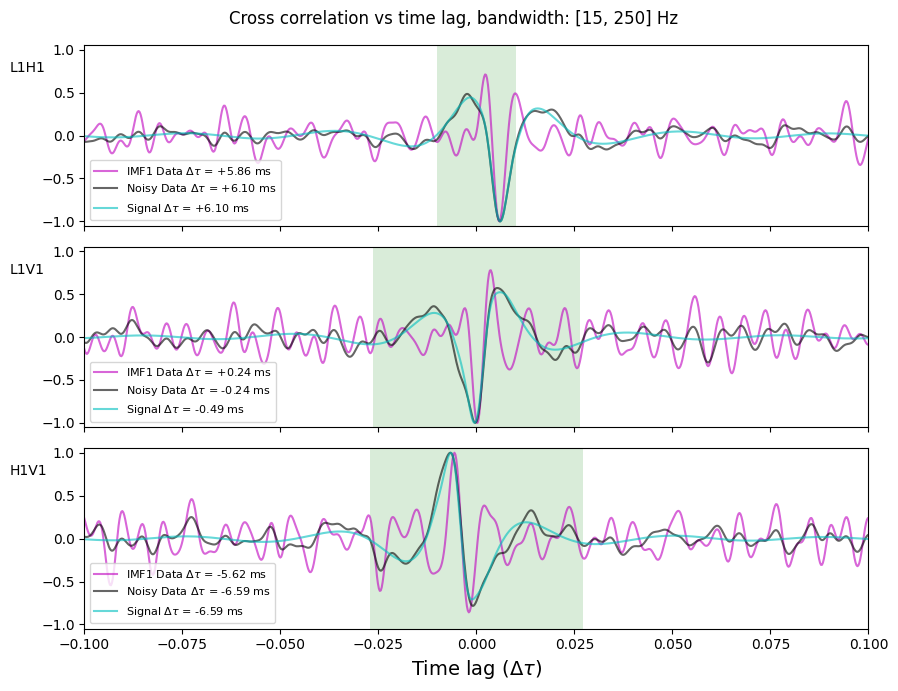

In [36]:
# Step 1: Extract IMF1 for each detector and store in a dictionary
imf_dict = {}
for detector in ifos:
    W = data_whitenbp[detector]  # Whitened data
    imfs = emd.sift.sift(W)      # Decompose into IMFs
    t = W
    print(f"{detector}: IMF1 shape {imfs[:,0].shape}, Time slice duration {t.duration}")

    # Store the IMF1 as a TimeSeries object
    imf_dict[detector] = pycbc.types.TimeSeries(
        imfs[:, 0], t._delta_t, epoch=t._epoch, copy=False
    )  # Extract IMF1 (first mode)

# Step 2: Setup plots
fig, ax = plt.subplots(len(ifos), 1, sharex=True, figsize=(9, 7))
fig.suptitle(f'Cross correlation vs time lag, bandwidth: {fband} Hz')
fig.subplots_adjust(top=0.95)

# Constants
light_time = {'L1H1': 0.010012846152267725, 'L1V1': 0.02644834101635671, 'H1V1': 0.027287979933397113}
tInterval = [-3.5, 1.5]
tRef = tTrigger

print(f'Trigger GPS time: {tTrigger} s')
print(f'Calculating cross-corr using {tInterval} s of data around reference GPS time {tRef}')
print(f'Reference time is {tRef - tTrigger} s away from the trigger time')

# Set default color cycle
mpl.rcParams['axes.prop_cycle'] = mpl.cycler(color=["m", "k", "c"])

# Step 3: Cross-correlation and plotting
p = 0
for i, ifoA in enumerate(ifos):
    for j, ifoB in enumerate(ifos):
        if j > i:
            print(f"Processing pair: {ifoA}-{ifoB}")
            
            # For IMF1 from different detectors (noisy data)
            lagxy, corrxy = calc_xcorr(imf_dict[ifoA], imf_dict[ifoB], tRef, tInterval, ifnormalize=True)
            print(f"Noisy IMF1: Lagxy shape {lagxy.shape}, Corrxy shape {corrxy.shape}")

            lt_AB = light_time.get(f'{ifoA}{ifoB}', None)
            if lt_AB is None:
                print(f"Light travel time for {ifoA}-{ifoB} not found!")
                continue

            k = np.where(np.abs(lagxy) <= lt_AB)
            idx = np.abs(corrxy[k]).argmax() + k[0][0]
            lag = lagxy[idx]

            ax[p].axvspan(-lt_AB, lt_AB, facecolor='g', alpha=0.15)
            ax[p].plot(lagxy, corrxy, label=rf'IMF1 Data $\Delta\tau$ = {lag*1000:+.2f} ms', alpha=0.6)

            # For noisy data (cross-correlation between raw data from detectors)
            lagxy, corrxy = calc_xcorr(data_whitenbp[ifoA], data_whitenbp[ifoB], tRef, tInterval, ifnormalize=True)
            print(f"Noisy Data: Lagxy shape {lagxy.shape}, Corrxy shape {corrxy.shape}")
            
            # Print the lag time for the noisy signal
            lt_AB = light_time.get(f'{ifoA}{ifoB}', None)
            if lt_AB is not None:
                k = np.where(np.abs(lagxy) <= lt_AB)
                idx = np.abs(corrxy[k]).argmax() + k[0][0]
                lag = lagxy[idx]
                print(f"Noisy Data Lag time (ms): {lag * 1000:.2f} ms")

            ax[p].plot(lagxy, corrxy, label=rf'Noisy Data $\Delta\tau$ = {lag * 1000:+.2f} ms', alpha=0.6)

            # For pure signals (no noise)
            lagxy, corrxy = calc_xcorr(signal_whitenbp[ifoA], signal_whitenbp[ifoB], tRef, tInterval, ifnormalize=True)
            print(f"Signal: Lagxy shape {lagxy.shape}, Corrxy shape {corrxy.shape}")

            k = np.where(np.abs(lagxy) <= lt_AB)
            idx = np.abs(corrxy[k]).argmax() + k[0][0]
            lag = lagxy[idx]

            ax[p].plot(lagxy, corrxy, label=rf'Signal $\Delta\tau$ = {lag*1000:+.2f} ms', alpha=0.6)

            ax[p].text(-0.095, 0.85, f'{ifoA}{ifoB}', transform=ax[p].transAxes)
            ax[p].set_xlim(-0.10, 0.10)
            ax[p].set_ylim(-1.05, 1.05)
            ax[p].legend(fontsize=8, loc=3)

            p += 1

plt.xlabel(r'Time lag ($\Delta\tau$)', fontsize=14)
plt.tight_layout()
plt.show()


In [39]:
def frequencytransform(fs, method, detector):
    """Perform EMD and frequency transform for a given detector."""
    W = data_whitenbp[detector]
    O_S = signal_whitenbp[detector]

    # Perform Empirical Mode Decomposition (EMD)
    imf = emd.sift.sift(W)
    imf_n = imf[:,1]

    # Perform frequency transform
    IP, IF, IA = emd.spectra.frequency_transform(imf, fs, method)

    # Hilbert-Huang Transform
    freq_range = (0, 1000, 40)
    f, hht = emd.spectra.hilberthuang(IF, IA, freq_range, sum_time=False)

    return IP, IF, IA, imf_n, f, hht

Processing EMD for L1...


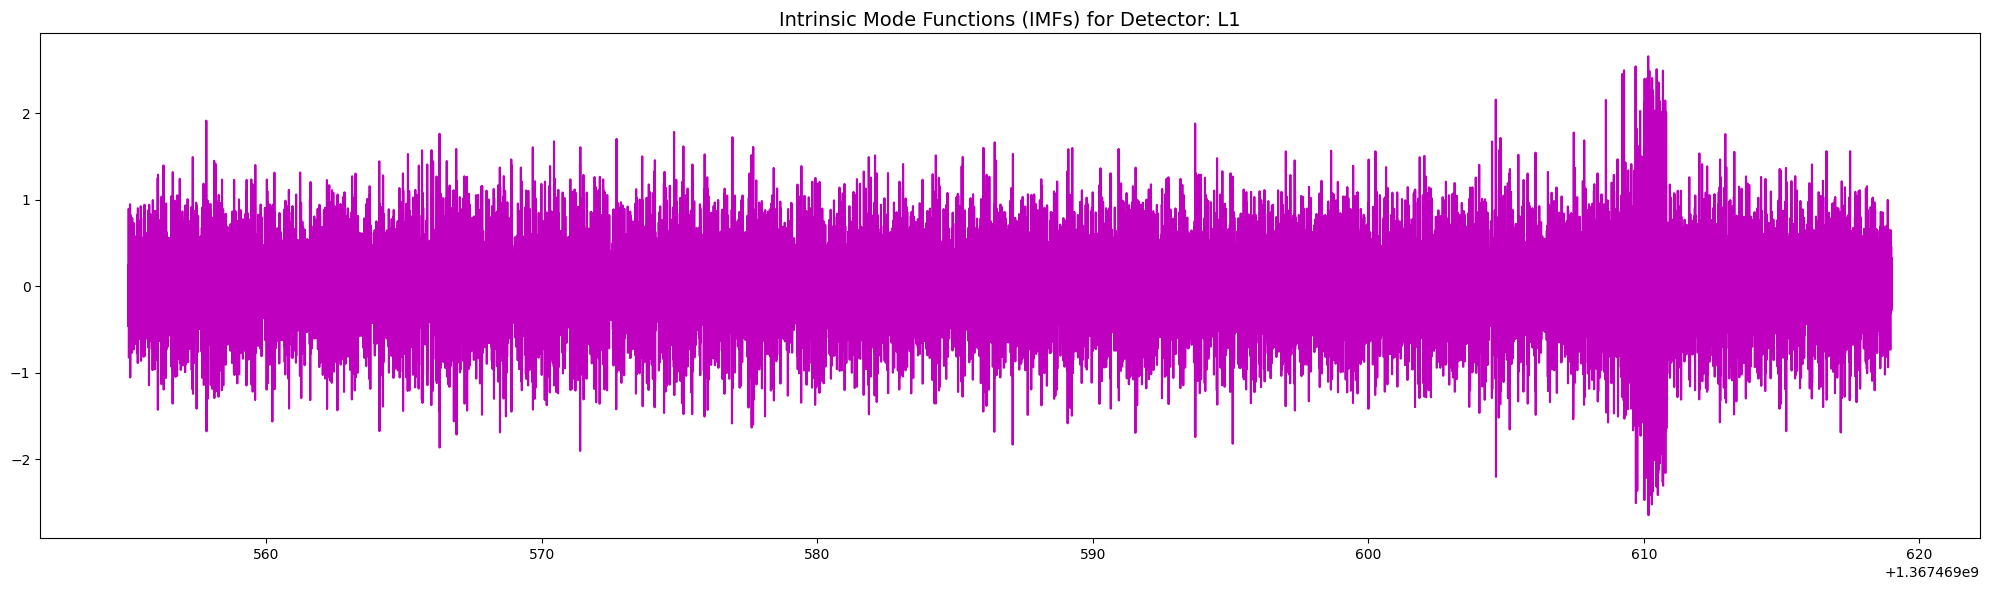

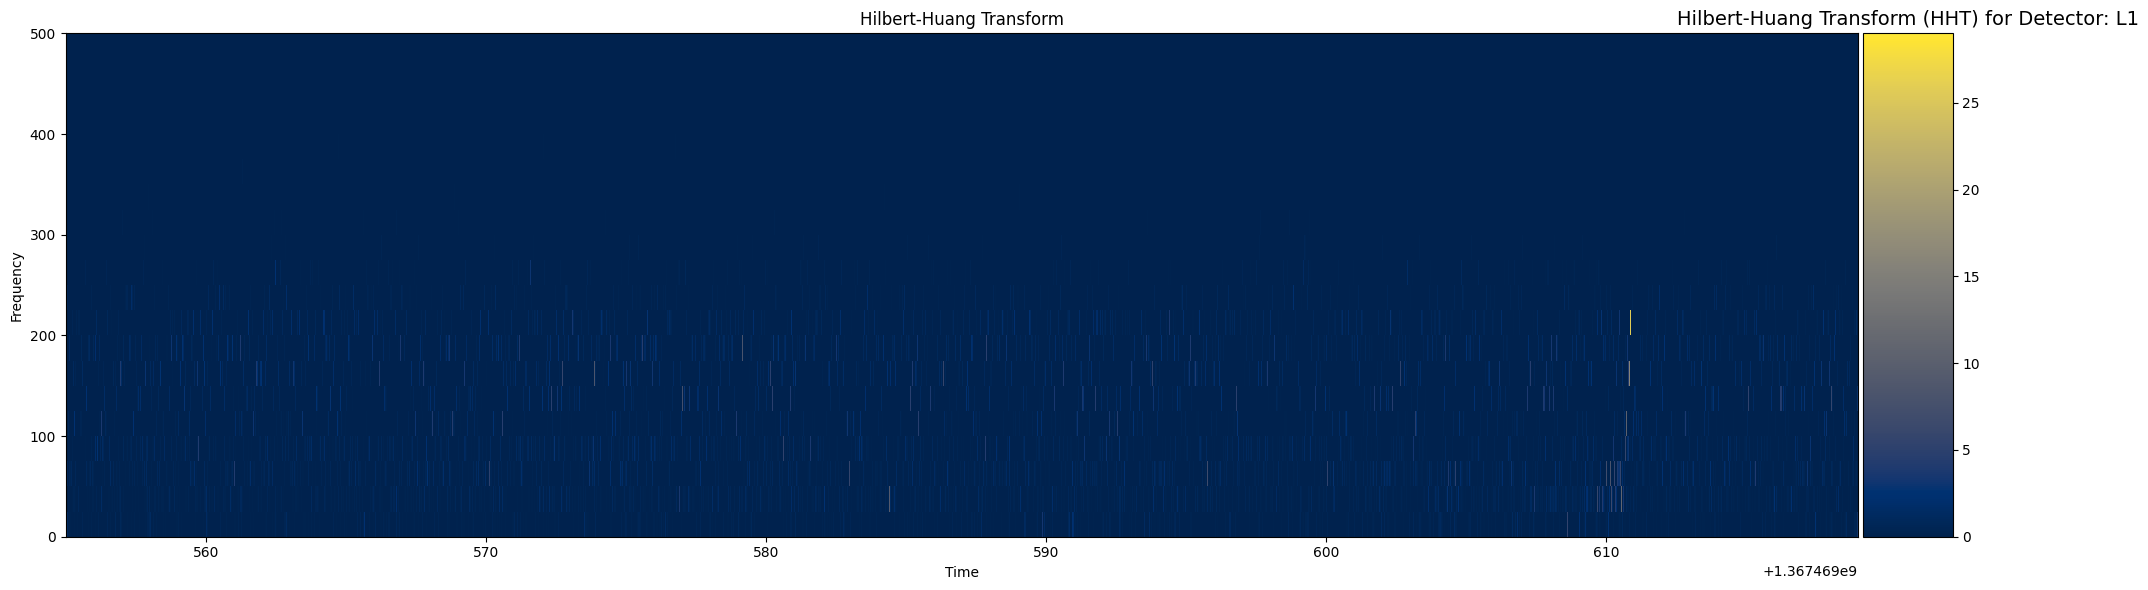

Processing EMD for H1...


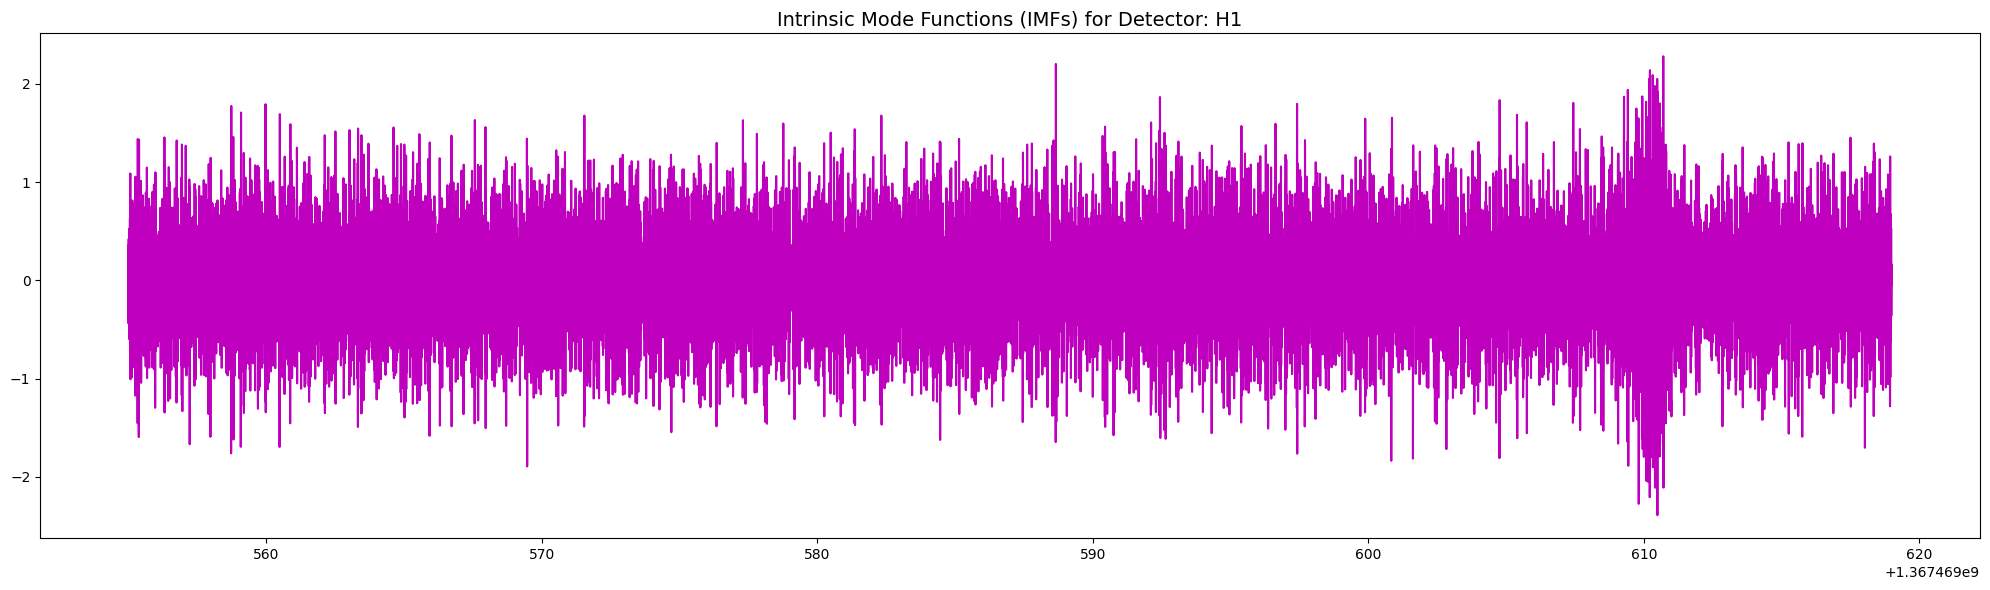

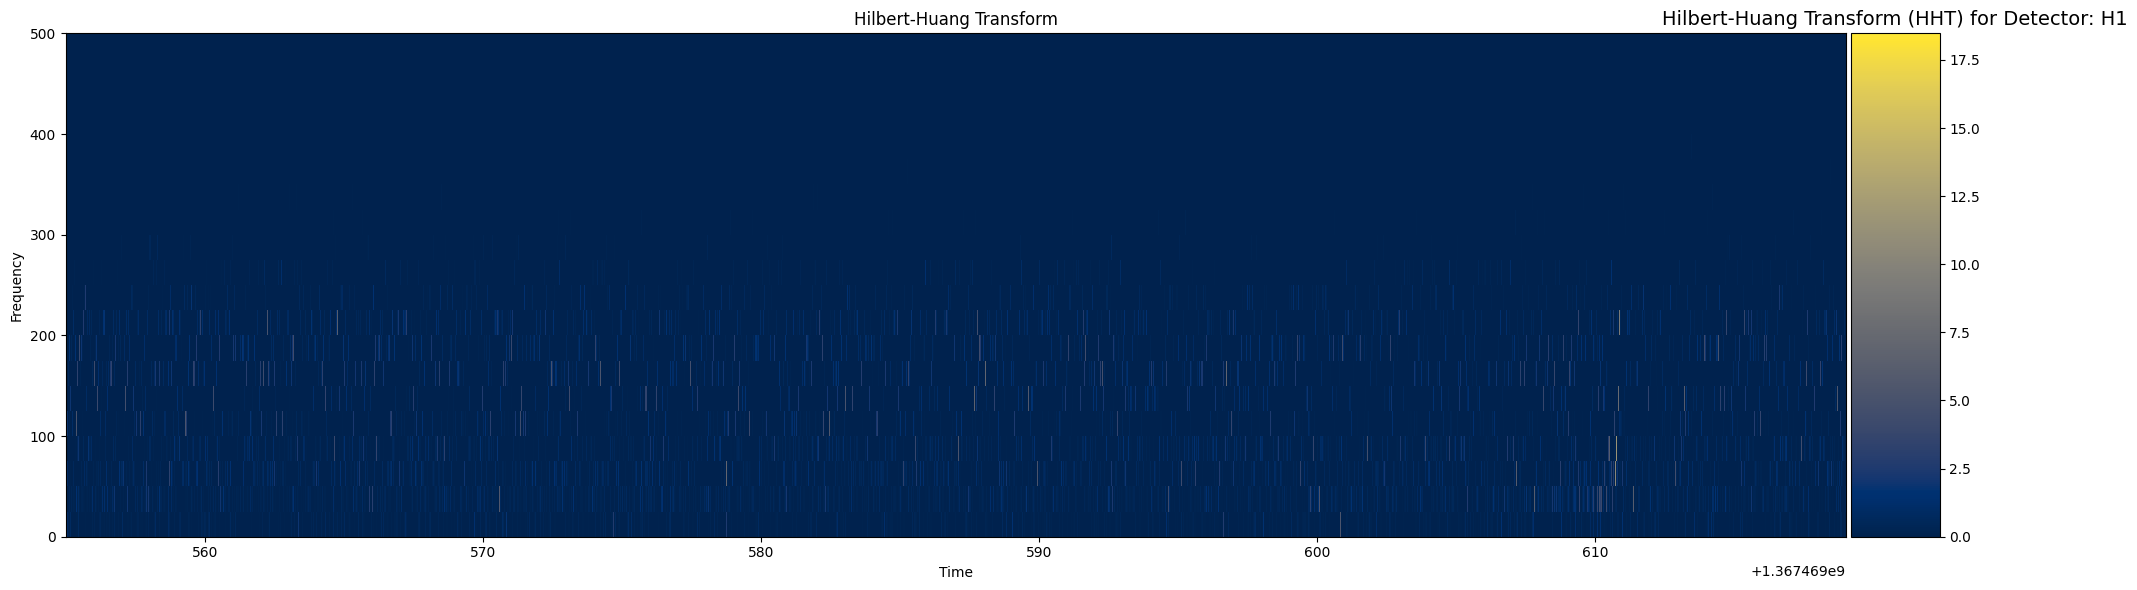

Processing EMD for V1...


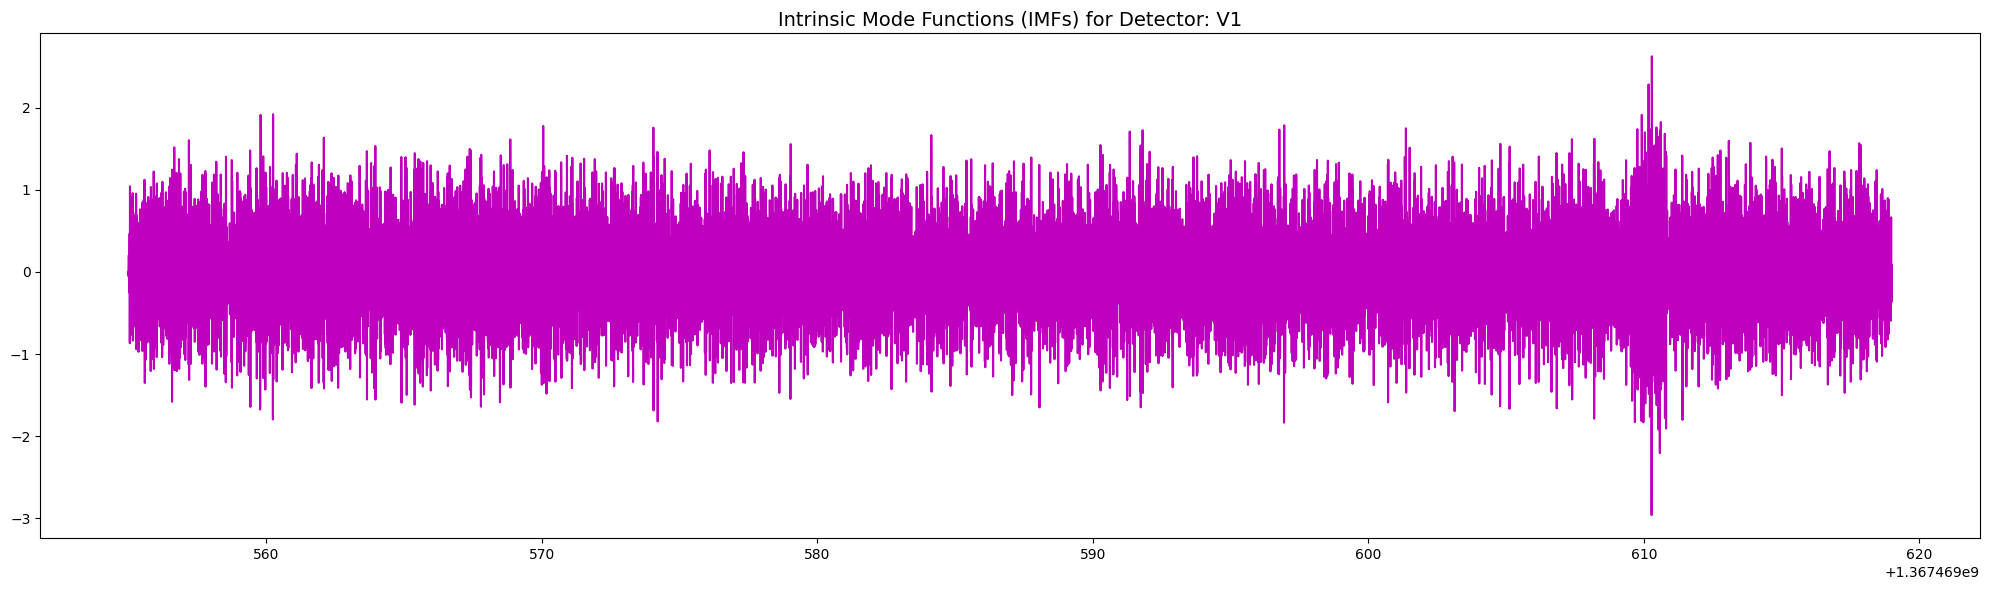

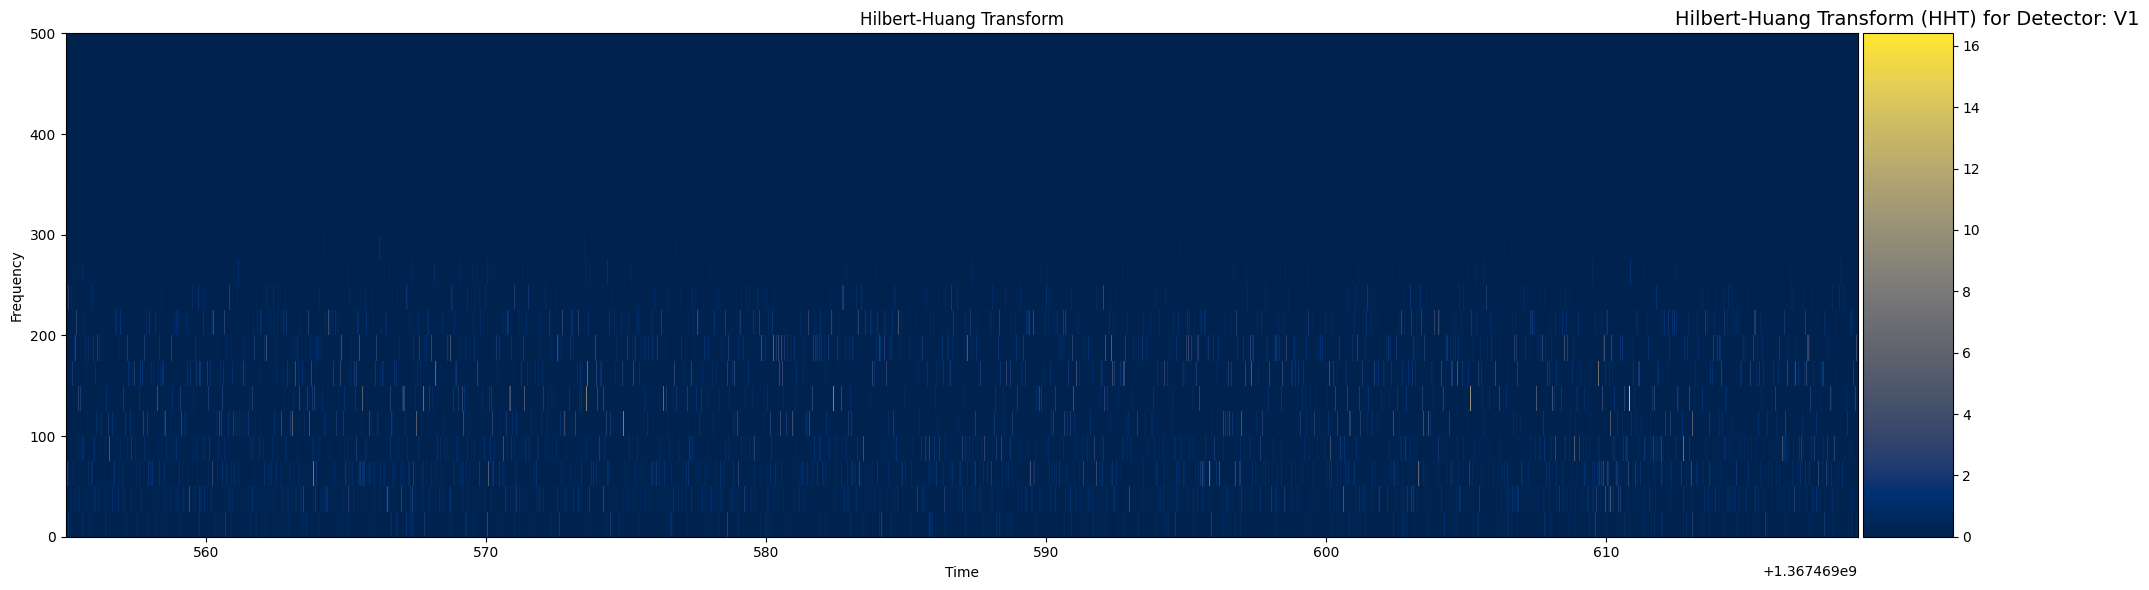

In [41]:

# Loop through detectors and generate IMFs and HHT plots
for detector in ifos:
    method = 'nht'  # Nonlinear Hilbert Transform
    print(f"Processing EMD for {detector}...")
    IP, IF, IA, imf_n, f, hht = frequencytransform(fsamp, method, detector)

    # Plot the IMFs
    plt.figure(figsize=(20, 6))
    plt.plot(t,imf_n)
    plt.title(f'Intrinsic Mode Functions (IMFs) for Detector: {detector}', fontsize=14)
    plt.tight_layout()
    plt.show()
    # Plot the Hilbert-Huang Transform (HHT)
    fig = plt.figure(figsize=(20, 6))
    t = data_whitenbp[detector].sample_times  # Use the time samples of the whitened bandpassed data
    emd.plotting.plot_hilberthuang(hht, t, f, freq_lims=(0, 500), fig=fig, cmap='cividis')
    plt.title(f'Hilbert-Huang Transform (HHT) for Detector: {detector}', fontsize=14)
    plt.tight_layout()
    plt.show()